# 03 · KNN model building

This notebook builds the K-Nearest Neighbors model track using the shared target `diagnosis` (`M` is the positive class). It excludes the record ID and the all-empty `Unnamed: 32` field. Imputation and scaling are inside the scikit-learn pipeline so they are fitted only on training folds. Scaling is essential for distance-based KNN because the measurements have different units and ranges.

**Primary metric:** malignant-class recall. Secondary metrics: precision, F1, accuracy, and ROC-AUC. This is a research exercise, not a clinical diagnostic tool.

**Validation design (same split as Logistic Regression):** reserve a stratified 20% test split before model selection. Split the remaining 80% into 60% train and 20% validation of all rows. Select KNN hyperparameters with 5-fold stratified cross-validation on the training partition only. Use validation once for the final development check and baseline comparison. Notebook 4 will load the exported pipeline and evaluate on the untouched test partition without retraining.

**Search budget declared before fitting:** 12 KNN configurations (6 neighbor counts × 2 voting-weight choices), each evaluated in 5 stratified folds: at most 60 candidate fits. Neighbor counts are `[3, 5, 7, 9, 11, 15]`; vote weights are `uniform` or `distance`; Minkowski distance with `p=2` (Euclidean distance) is fixed. Include one `most_frequent` DummyClassifier baseline. Select by mean cross-validation malignant recall; exact ties use GridSearchCV's first-best rule over the declared ascending neighbor-count grid, favoring the smaller neighbor count. No search expansion after seeing results.

The dataset contains 569 rows, with 357 benign and 212 malignant cases. Its size supports a compact classical-model comparison but leaves uncertainty about split sensitivity. KNN is sensitive to feature scale, neighbor count, local density, and correlated measurements; the scale and neighbor choice are handled in a leakage-safe pipeline and fixed-budget search.

In [1]:
from pathlib import Path
import json
import platform
import random
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
TARGET = 'diagnosis'
ID_COLUMN = 'id'
POSITIVE_LABEL = 'M'
LABEL_TO_INT = {'B': 0, 'M': 1}
cwd = Path.cwd().resolve()
REPO_ROOT = next((candidate for candidate in [cwd, *cwd.parents]
                  if (candidate / 'data/raw/Raw_Breast_Cancer_Data.csv').exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate repository data/raw/Raw_Breast_Cancer_Data.csv from the notebook working directory.')
DATA_PATH = REPO_ROOT / 'data/raw/Raw_Breast_Cancer_Data.csv'
MODEL_DIR = REPO_ROOT / 'models/KNN'
REPORT_DIR = REPO_ROOT / 'reports/figures/KNN'
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}')
print('Global random seed:', SEED)

Python 3.13.3 | pandas 3.0.5 | NumPy 2.5.2 | scikit-learn 1.9.0
Global random seed: 42


In [2]:
df_raw = pd.read_csv(DATA_PATH)
empty_columns = df_raw.columns[df_raw.isna().all()].tolist()
df = df_raw.drop(columns=empty_columns).copy()
X = df.drop(columns=[TARGET, ID_COLUMN])
y = df[TARGET].map(LABEL_TO_INT)
if y.isna().any():
    raise ValueError('Unexpected or missing diagnosis label; inspect source data before modeling.')
if set(y.unique()) != {0, 1}:
    raise ValueError('Expected both benign (B) and malignant (M) classes.')
print('Dataset shape after excluding all-empty field:', df.shape)
print('Predictor count:', X.shape[1])
print('Target counts (0=benign, 1=malignant):')
display(y.value_counts().sort_index().rename(index={0: 'B (benign)', 1: 'M (malignant)'}).to_frame('count'))
print('Missing predictor cells:', int(X.isna().sum().sum()))
print('Excluded all-empty columns:', empty_columns)

Dataset shape after excluding all-empty field: (569, 32)
Predictor count: 30
Target counts (0=benign, 1=malignant):


,count
diagnosis,
B (benign),357
M (malignant),212


Missing predictor cells: 0
Excluded all-empty columns: ['Unnamed: 32']


In [3]:
# Match the split recipe from the Logistic Regression track exactly.
all_idx = np.arange(len(y))
dev_idx, test_idx = train_test_split(
    all_idx, test_size=0.20, random_state=SEED, stratify=y)
train_idx, val_idx = train_test_split(
    dev_idx, test_size=0.25, random_state=SEED, stratify=y.iloc[dev_idx])
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
print(f'Train: {len(train_idx)} | Validation: {len(val_idx)} | Held-out test: {len(test_idx)}')
for split_name, split_y in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{split_name} class proportions: {split_y.value_counts(normalize=True).sort_index().round(3).to_dict()}')

Train: 341 | Validation: 114 | Held-out test: 114
train class proportions: {0: 0.628, 1: 0.372}
validation class proportions: {0: 0.623, 1: 0.377}
test class proportions: {0: 0.632, 1: 0.368}


## Baseline and scoring

The `most_frequent` baseline predicts the majority class from training labels. It provides a transparent reference, not a useful screening model by design. Evaluate it on validation data using malignant recall as the primary measure; do not use the held-out test partition here.

In [4]:
def metric_row(y_true, y_pred, y_score=None):
    result = {
        'malignant_recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'accuracy': accuracy_score(y_true, y_pred),
    }
    result['roc_auc'] = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return result

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_val_pred = baseline.predict(X_val)
baseline_val_score = baseline.predict_proba(X_val)[:, list(baseline.classes_).index(1)] if 1 in baseline.classes_ else None
baseline_val_metrics = metric_row(y_val, baseline_val_pred, baseline_val_score)
display(pd.DataFrame([baseline_val_metrics], index=['DummyClassifier (validation)']))
print('Baseline predicts one class only; zero malignant recall is expected from this strategy.')

,malignant_recall,precision,f1,accuracy,roc_auc
DummyClassifier (validation),0.0,0.0,0.0,0.622807,0.5


Baseline predicts one class only; zero malignant recall is expected from this strategy.


## KNN search

Each cross-validation fold fits the median imputer and standard scaler on that fold's training rows only. The imputer is a train-fitted safeguard and is a no-op if the predictor columns have no missing values. KNN then measures Euclidean distances in the scaled feature space. The fixed search tests neighbor count and whether neighbors vote equally or by inverse distance.

In [5]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(metric='minkowski', p=2, n_jobs=1)),
])
NEIGHBOR_COUNTS = [3, 5, 7, 9, 11, 15]
VOTE_WEIGHTS = ['uniform', 'distance']
param_grid = {
    'model__n_neighbors': NEIGHBOR_COUNTS,
    'model__weights': VOTE_WEIGHTS,
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='recall',
    cv=cv,
    refit=True,
    return_train_score=True,
    n_jobs=-1,
    error_score='raise',
)
search.fit(X_train, y_train)
assert len(search.cv_results_['params']) == 12
print('Configurations evaluated:', len(search.cv_results_['params']))
print('Fold fits for candidate models:', len(search.cv_results_['params']) * cv.get_n_splits())
print('Selected parameters (by mean 5-fold malignant recall):', search.best_params_)
print('Best mean CV malignant recall:', round(search.best_score_, 4))

Configurations evaluated: 12
Fold fits for candidate models: 60
Selected parameters (by mean 5-fold malignant recall): {'model__n_neighbors': 5, 'model__weights': 'uniform'}
Best mean CV malignant recall: 0.9222


In [6]:
# Record every candidate configuration and its training-only CV results.
run_timestamp = datetime.now(timezone.utc).isoformat()
experiment_log = pd.DataFrame({
    'model_name': 'KNeighborsClassifier',
    'n_neighbors': [p['model__n_neighbors'] for p in search.cv_results_['params']],
    'weights': [p['model__weights'] for p in search.cv_results_['params']],
    'distance': 'minkowski_p2_euclidean',
    'primary_metric': 'malignant_recall',
    'evaluation_split': '5-fold stratified CV on training partition',
    'mean_cv_malignant_recall': search.cv_results_['mean_test_score'],
    'std_cv_malignant_recall': search.cv_results_['std_test_score'],
    'mean_cv_train_recall': search.cv_results_['mean_train_score'],
    'run_timestamp_utc': run_timestamp,
})
REPORT_DIR.mkdir(parents=True, exist_ok=True)
log_path = REPORT_DIR / 'experiment_log.csv'
experiment_log.to_csv(log_path, index=False)
display(experiment_log.sort_values(['mean_cv_malignant_recall', 'std_cv_malignant_recall'], ascending=[False, True]))
print('Experiment log saved to:', log_path)

,model_name,n_neighbors,weights,distance,primary_metric,evaluation_split,mean_cv_malignant_recall,std_cv_malignant_recall,mean_cv_train_recall,run_timestamp_utc
2,KNeighborsClassifier,5,uniform,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.922154,0.080540,0.938983,2026-09-27T02:06:07.228718+00:00
3,KNeighborsClassifier,5,distance,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.922154,0.080540,1.000000,2026-09-27T02:06:07.228718+00:00
0,KNeighborsClassifier,3,uniform,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.914154,0.055949,0.946884,2026-09-27T02:06:07.228718+00:00
1,KNeighborsClassifier,3,distance,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.914154,0.055949,1.000000,2026-09-27T02:06:07.228718+00:00
7,KNeighborsClassifier,9,distance,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.883077,0.096578,1.000000,2026-09-27T02:06:07.228718+00:00
8,KNeighborsClassifier,11,uniform,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.883077,0.099837,0.915356,2026-09-27T02:06:07.228718+00:00
9,KNeighborsClassifier,11,distance,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.883077,0.099837,1.000000,2026-09-27T02:06:07.228718+00:00
11,KNeighborsClassifier,15,distance,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.875385,0.097922,1.000000,2026-09-27T02:06:07.228718+00:00
4,KNeighborsClassifier,7,uniform,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.875077,0.091392,0.937022,2026-09-27T02:06:07.228718+00:00
5,KNeighborsClassifier,7,distance,minkowski_p2_euclidean,malignant_recall,5-fold stratified CV on training partition,0.875077,0.091392,1.000000,2026-09-27T02:06:07.228718+00:00


Experiment log saved to: C:\Projects_Tracking\Breast_Cancer_Prediction\reports\figures\KNN\experiment_log.csv


## One-time validation comparison and overfitting review

The selected candidate is chosen from training-only cross-validation. Compare it with the baseline on the validation partition once. The experiment log includes mean and standard deviation of fold recall plus training-fold recall; a train/CV gap and fold variability indicate potential overfitting or split sensitivity. Do not repeatedly inspect validation to search for better settings.

,malignant_recall,precision,f1,accuracy,roc_auc
DummyClassifier,0.000000,0.0,0.000000,0.622807,0.500000
KNN (CV-selected),0.930233,1.0,0.963855,0.973684,0.994759


Primary-metric validation difference (KNN minus baseline): 0.9302


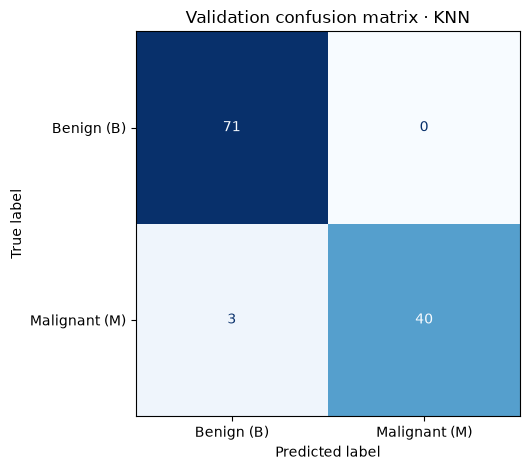

In [7]:
selected_pipeline = search.best_estimator_
val_pred = selected_pipeline.predict(X_val)
val_score = selected_pipeline.predict_proba(X_val)[:, list(selected_pipeline.classes_).index(1)]
selected_val_metrics = metric_row(y_val, val_pred, val_score)
comparison = pd.DataFrame(
    [baseline_val_metrics, selected_val_metrics],
    index=['DummyClassifier', 'KNN (CV-selected)'])
display(comparison)
print('Primary-metric validation difference (KNN minus baseline):',
      round(selected_val_metrics['malignant_recall'] - baseline_val_metrics['malignant_recall'], 4))
ConfusionMatrixDisplay.from_predictions(
    y_val, val_pred, labels=[0, 1], display_labels=['Benign (B)', 'Malignant (M)'],
    cmap='Blues', colorbar=False)
plt.title('Validation confusion matrix · KNN')
plt.tight_layout()
plt.show()

In [8]:
# Refit the fixed, selected pipeline on train + validation for final held-out testing.
# No test rows or labels are used for fitting.
X_development = pd.concat([X_train, X_val], axis=0)
y_development = pd.concat([y_train, y_val], axis=0)
final_pipeline = search.best_estimator_
final_pipeline.fit(X_development, y_development)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / 'knn_pipeline.joblib'
joblib.dump(final_pipeline, model_path)
metadata = {
    'model': 'KNeighborsClassifier',
    'target': TARGET,
    'positive_label': POSITIVE_LABEL,
    'label_mapping': LABEL_TO_INT,
    'features': X.columns.tolist(),
    'excluded_columns': [ID_COLUMN] + empty_columns,
    'selected_parameters': search.best_params_,
    'distance': 'minkowski_p2_euclidean',
    'primary_metric': 'malignant_recall',
    'selection_metric': 'mean 5-fold stratified CV malignant recall on training partition',
    'seed': SEED,
    'split_sizes': {'train': int(len(train_idx)), 'validation': int(len(val_idx)), 'test': int(len(test_idx))},
    'test_partition_note': 'Held out for Notebook 4; not used for fitting or model selection.',
    'search_budget': {'configurations': 12, 'folds': 5, 'candidate_fits_max': 60},
}
metadata_path = REPORT_DIR / 'model_metadata.json'
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Final KNN pipeline saved to:', model_path)
print('Metadata saved to:', metadata_path)
print('Test split was not evaluated in this notebook.')

Final KNN pipeline saved to: C:\Projects_Tracking\Breast_Cancer_Prediction\models\KNN\knn_pipeline.joblib
Metadata saved to: C:\Projects_Tracking\Breast_Cancer_Prediction\reports\figures\KNN\model_metadata.json
Test split was not evaluated in this notebook.


## Conclusion to complete after execution

After running the notebook, cite the selected row in `reports/figures/KNN/experiment_log.csv`, including its mean and standard deviation for cross-validation malignant recall and its training-fold recall. Report the validation metrics and baseline comparison without inventing values. Do not use the held-out test result here; Notebook 4 evaluates that set once without retraining.

### Self-critique

KNN may be sensitive to this dataset's correlated predictors, local sample density, and the chosen scaling and neighbor count. Searching only 12 configurations limits tuning but may not identify the best possible neighborhood. A small, single-source dataset also leaves uncertainty about new populations. The held-out test set, secondary metrics, and explicit limitations help quantify this specific model's result but do not establish clinical usefulness.